TensorFlow: 2.21.0
GPU: []
训练集： (453716, 100)
测试集： (113429, 100)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
1596/1596 ━━━━━━━━━━━━━━━━━━━━ 182s 113ms/step - accuracy: 0.7102 - loss: 0.7896 - val_accuracy: 0.7438 - val_loss: 0.6900
Epoch 2/5
1596/1596 ━━━━━━━━━━━━━━━━━━━━ 184s 115ms/step - accuracy: 0.7563 - loss: 0.6533 - val_accuracy: 0.7602 - val_loss: 0.6488
Epoch 3/5
1596/1596 ━━━━━━━━━━━━━━━━━━━━ 188s 118ms/step - accuracy: 0.7822 - loss: 0.5881 - val_accuracy: 0.7681 - val_loss: 0.6377
Epoch 4/5
1596/1596 ━━━━━━━━━━━━━━━━━━━━ 237s 149ms/step - accuracy: 0.8018 - loss: 0.5378 - val_accuracy: 0.7766 - val_loss: 0.6277
Epoch 5/5
1596/1596 ━━━━━━━━━━━━━━━━━━━━ 244s 153ms/step - accuracy: 0.8179 - loss: 0.4967 - val_accuracy: 0.7794 - val_loss: 0.6374
444/444 ━━━━━━━━━━━━━━━━━━━━ 25s 57ms/step
Accuracy: 0.7779668338784614
Macro F1: 0.6042106548564421
Weighted F1: 0.7650345314427293
              precision    recall  f1-score   support

      1 star       0.69      0.75      0.72     10393
     2 stars       0.49      0.40      0.44      5951
     3 stars       0.48      0.54      

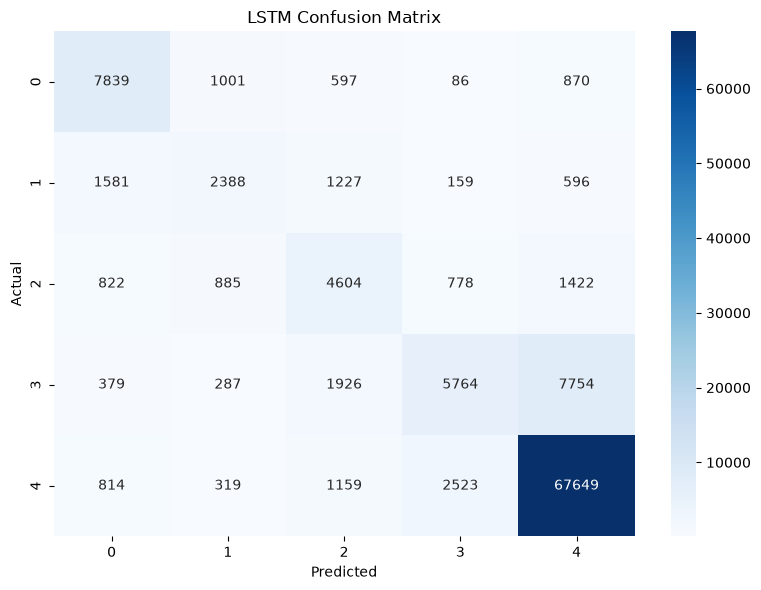

LSTM model saved successfully!


In [2]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score,
    classification_report, confusion_matrix
)

# 固定随机种子
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

# 1. 加载数据
df = pd.read_csv("../data/processed/reviews_cleaned.csv")
df = df.dropna(subset=["Text", "Score"])

X = df["Text"].astype(str).values
y = df["Score"].astype(int).values - 1

# 2. 划分数据集
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. 文本序列化
MAX_WORDS = 20000
MAX_LEN = 100

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    X_train_seq, maxlen=MAX_LEN, padding="post", truncating="post"
)
X_test_pad = pad_sequences(
    X_test_seq, maxlen=MAX_LEN, padding="post", truncating="post"
)

print("训练集：", X_train_pad.shape)
print("测试集：", X_test_pad.shape)

# 4. 构建 LSTM
model = Sequential([
    Embedding(MAX_WORDS, 128, mask_zero=True),
    LSTM(64, dropout=0.2, recurrent_dropout=0.0),
    Dropout(0.3),
    Dense(5, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# 5. 模型训练
history = model.fit(
    X_train_pad,
    y_train,
    validation_split=0.1,
    epochs=5,
    batch_size=256,
    verbose=1
)

# 6. 测试集评估
y_prob = model.predict(X_test_pad, batch_size=256)
y_pred = np.argmax(y_prob, axis=1)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Macro F1:", f1_score(y_test, y_pred, average="macro"))
print("Weighted F1:", f1_score(y_test, y_pred, average="weighted"))

print(classification_report(
    y_test, y_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=["1 star", "2 stars", "3 stars", "4 stars", "5 stars"],
    zero_division=0
))

# 7. 混淆矩阵
plt.figure(figsize=(8, 6))

sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("LSTM Confusion Matrix")
plt.tight_layout()

plt.savefig("../results/figures/lstm_confusion_matrix.png", dpi=300)
plt.show()

# 8. 保存模型
model.save("../results/lstm_model.keras")

print("LSTM model saved successfully!")

In [3]:

import pandas as pd
from pathlib import Path

# 1. 整理模型对比数据
results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": 0.7125514639,
        "Macro F1": 0.5996397164,
        "Weighted F1": 0.7311476185
    },
    {
        "Model": "LSTM",
        "Accuracy": 0.7779668339,
        "Macro F1": 0.6042106549,
        "Weighted F1": 0.7650345314
    }
])

# 2. 创建保存目录（不存在则自动创建）
output_dir = Path("../results/metrics")
output_dir.mkdir(parents=True, exist_ok=True)

# 3. 保存 CSV 文件
output_path = output_dir / "model_comparison.csv"
results.to_csv(output_path, index=False)

print("模型对比结果已保存：", output_path.resolve())
print(results)


模型对比结果已保存： D:\Projects\amazon-review-sentiment-classification\results\metrics\model_comparison.csv
                 Model  Accuracy  Macro F1  Weighted F1
0  Logistic Regression  0.712551  0.599640     0.731148
1                 LSTM  0.777967  0.604211     0.765035


In [4]:

import json
import sys
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
from pathlib import Path

# 1. 整理实验配置
config = {
    "project": "Amazon Review Sentiment Classification",

    "dataset": {
        "name": "Amazon Fine Food Reviews",
        "source": "Kaggle - SNAP",
        "raw_file": "data/raw/Reviews.csv",
        "cleaned_file": "data/processed/reviews_cleaned.csv",
        "num_classes": 5,
        "label": "Score",
        "cleaning": [
            "Remove rows with missing Text or Score",
            "Remove empty review texts",
            "Remove duplicate UserId, ProductId and Text records"
        ]
    },

    "data_split": {
        "train_test_ratio": "80:20",
        "random_state": 42,
        "stratify": True
    },

    "logistic_regression": {
        "feature_extraction": "TF-IDF",
        "max_features": 20000,
        "ngram_range": [1, 2],
        "min_df": 3,
        "max_df": 0.95,
        "sublinear_tf": True,
        "max_iter": 1000,
        "class_weight": "balanced",
        "solver": "lbfgs"
    },

    "lstm": {
        "tokenizer_num_words": 20000,
        "max_sequence_length": 100,
        "embedding_dim": 128,
        "lstm_units": 64,
        "lstm_dropout": 0.2,
        "recurrent_dropout": 0.0,
        "dropout": 0.3,
        "optimizer": "Adam",
        "loss": "sparse_categorical_crossentropy",
        "epochs": 5,
        "batch_size": 256,
        "validation_split": 0.1
    },

    "environment": {
        "python": sys.version.split()[0],
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__,
        "tensorflow": tf.__version__
    }
}

# 2. 创建保存目录
output_dir = Path("../results/metrics")
output_dir.mkdir(parents=True, exist_ok=True)

# 3. 保存 JSON
output_path = output_dir / "experiment_config.json"

with open(output_path, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=4, ensure_ascii=False)

print("实验配置已保存：", output_path.resolve())


实验配置已保存： D:\Projects\amazon-review-sentiment-classification\results\metrics\experiment_config.json
